In [ ]:
import numpy as np
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score,
    average_precision_score,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

## <b>Global Variables.</b>

In [2]:
# Paths for BTCUSDT.
PATH_BINANCE_PERP_BTCUSDT_LOB       = r'data\binance_booktickers\perp_btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_LIQUID    = r'data\binance_liquidations\perp_btcusdt.parquet'
PATH_BYBIT_PERP_BTCUSDT_LIQUID      = r'data\bybit_liquidations\btcusdt.parquet'
PATH_BINANCE_PERP_BTCUSDT_TRADES    = r'data\binance_trades\perp_btcusdt.parquet'

# Paths for ETHUSDT.
PATH_BINANCE_PERP_ETHUSDT_LOB       = r'data\binance_booktickers\perp_ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_LIQUID    = r'data\binance_liquidations\perp_ethusdt.parquet'
PATH_BYBIT_PERP_ETHUSDT_LIQUID      = r'data\bybit_liquidations\ethusdt.parquet'
PATH_BINANCE_PERP_ETHUSDT_TRADES    = r'data\binance_trades\perp_ethusdt.parquet'

# All .parquet files.
PARQUET_FILES = {
    "binance_perp_btcusdt_lob": PATH_BINANCE_PERP_BTCUSDT_LOB,
    "binance_perp_btcusdt_liquid": PATH_BINANCE_PERP_BTCUSDT_LIQUID,
    "bybit_perp_btcusdt_liquid": PATH_BYBIT_PERP_BTCUSDT_LIQUID,
    "binance_perp_btcusdt_trades": PATH_BINANCE_PERP_BTCUSDT_TRADES,

    "binance_perp_ethusdt_lob": PATH_BINANCE_PERP_ETHUSDT_LOB,
    "binance_perp_ethusdt_liquid": PATH_BINANCE_PERP_ETHUSDT_LIQUID,
    "bybit_perp_ethusdt_liquid": PATH_BYBIT_PERP_ETHUSDT_LIQUID,
    "binance_perp_ethusdt_trades": PATH_BINANCE_PERP_ETHUSDT_TRADES,
}

In [3]:
# parse the data.
lf_btc_trades       = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_TRADES)
lf_btc_lob          = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_LOB)
lf_btc_liq_binance  = pl.scan_parquet(PATH_BINANCE_PERP_BTCUSDT_LIQUID)
lf_btc_liq_bybit    = pl.scan_parquet(PATH_BYBIT_PERP_BTCUSDT_LIQUID)

lf_eth_trades       = pl.scan_parquet(PATH_BINANCE_PERP_ETHUSDT_TRADES)
lf_eth_lob          = pl.scan_parquet(PATH_BINANCE_PERP_ETHUSDT_LOB)
lf_eth_liq_binance  = pl.scan_parquet(PATH_BINANCE_PERP_ETHUSDT_LIQUID)
lf_eth_liq_bybit    = pl.scan_parquet(PATH_BYBIT_PERP_ETHUSDT_LIQUID)

In [ ]:
feature_cols = [
    # Volatility.
    "abs_return_1m",
    "abs_return_mean_15m",
    "abs_return_mean_60m",
    "rv_60m",

    # Trading activity.
    "trade_volume",
    "log_trade_volume",
    "trade_volume_sum_60m",
    "trade_imbalance",

    # LOB liquidity proxy.
    "half_spread_bps",
    "half_spread_mean_30m",
    "half_spread_mean_60m",
    "half_spread_zscore_60m",

    # Liquidation pressure.
    "liq_total_volume",
    "log_liq_total_volume",
    "liq_total_sum_15m",
    "liq_total_sum_60m",
    "liq_imbalance",
    "liq_imbalance_60m",
    "liq_zscore_60m",

    # Illiquidity.
    "amihud_per_1m_usd",
    "amihud_median_60m",
]

In [5]:
def build_ml_liquidation_table(
    lf_trades: pl.LazyFrame,
    lf_lob: pl.LazyFrame,
    lf_liq_binance: pl.LazyFrame,
    lf_liq_bybit: pl.LazyFrame,
    horizon: int = 15,
) -> pl.DataFrame:
    """
    Builds minute-level ML table directly from LazyFrames.

    Features use only information available at current or past minutes.
    Target uses future liquidation volume over the next horizon minutes.
    """

    # Trades.
    lf_trades_min = (
        lf_trades
        .select(
            (pl.col("timestamp") // 60_000_000).alias("minute"),
            (pl.col("price") * pl.col("amount")).alias("dollar_amount"),
            pl.col("side"),
        )
        .group_by("minute")
        .agg(
            pl.col("dollar_amount").sum().alias("trade_volume"),
            pl.len().alias("trade_count"),

            pl.col("dollar_amount")
            .filter(pl.col("side") == "buy")
            .sum()
            .alias("buy_volume"),

            pl.col("dollar_amount")
            .filter(pl.col("side") == "sell")
            .sum()
            .alias("sell_volume"),
        )
        .with_columns(
            pl.col("buy_volume").fill_null(0),
            pl.col("sell_volume").fill_null(0),
        )
        .with_columns(
            (
                (pl.col("buy_volume") - pl.col("sell_volume"))
                / (pl.col("buy_volume") + pl.col("sell_volume"))
            ).alias("trade_imbalance")
        )
        .sort("minute")
    )


    # LOB.
    lf_lob_min = (
        lf_lob
        .select(
            (pl.col("timestamp") // 60_000_000).alias("minute"),
            pl.col("bid_price"),
            pl.col("ask_price"),
        )
        .with_columns(
            ((pl.col("bid_price") + pl.col("ask_price")) / 2).alias("mid"),
            (pl.col("ask_price") - pl.col("bid_price")).alias("spread"),
            (
                (pl.col("ask_price") - pl.col("bid_price"))
                / (2 * ((pl.col("bid_price") + pl.col("ask_price")) / 2))
                * 10_000
            ).alias("half_spread_bps_raw"),
        )
        .group_by("minute")
        .agg(
            pl.col("mid").last().alias("mid_close"),
            pl.col("mid").std().alias("mid_intraminute_std"),
            pl.col("spread").mean().alias("avg_spread"),
            pl.col("half_spread_bps_raw").mean().alias("half_spread_bps"),
            pl.len().alias("lob_updates"),
        )
        .sort("minute")
    )


    # Liquidations.
    def prepare_liq(lf: pl.LazyFrame, exchange: str) -> pl.LazyFrame:
        if exchange == "bybit":
            lf = lf.with_columns(
                (pl.col("timestamp") + 200_000).alias("timestamp")
            )

        return (
            lf
            .select(
                (pl.col("timestamp") // 60_000_000).alias("minute"),
                (pl.col("price") * pl.col("amount")).alias("liq_dollar_amount"),
                pl.col("side"),
                pl.lit(exchange).alias("exchange"),
            )
        )

    lf_liq_min = (
        pl.concat(
            [
                prepare_liq(lf_liq_binance, "binance"),
                prepare_liq(lf_liq_bybit, "bybit"),
            ]
        )
        .group_by("minute")
        .agg(
            pl.col("liq_dollar_amount").sum().alias("liq_total_volume"),
            pl.len().alias("liq_event_count"),

            pl.col("liq_dollar_amount")
            .filter(pl.col("side") == "buy")
            .sum()
            .alias("liq_buy_volume"),

            pl.col("liq_dollar_amount")
            .filter(pl.col("side") == "sell")
            .sum()
            .alias("liq_sell_volume"),
        )
        .with_columns(
            pl.col("liq_buy_volume").fill_null(0),
            pl.col("liq_sell_volume").fill_null(0),
        )
        .with_columns(
            (pl.col("liq_buy_volume") - pl.col("liq_sell_volume")).alias("liq_net_volume"),
            (
                (pl.col("liq_buy_volume") - pl.col("liq_sell_volume"))
                / (pl.col("liq_buy_volume") + pl.col("liq_sell_volume"))
            ).alias("liq_imbalance"),
        )
        .sort("minute")
    )


    # Join all.
    df = (
        lf_lob_min
        .join(lf_trades_min, on="minute", how="left")
        .join(lf_liq_min, on="minute", how="left")
        .sort("minute")
        .collect(engine="streaming")
    )


    # Fill missing activity with zeros.
    zero_cols = [
        "trade_volume",
        "trade_count",
        "buy_volume",
        "sell_volume",
        "trade_imbalance",
        "liq_total_volume",
        "liq_event_count",
        "liq_buy_volume",
        "liq_sell_volume",
        "liq_net_volume",
        "liq_imbalance",
    ]

    df = df.with_columns(
        [
            pl.col(col).fill_null(0)
            for col in zero_cols
            if col in df.columns
        ]
    )


    # Returns and transforms.
    df = (
        df
        .with_columns(
            pl.col("mid_close").log().diff().alias("return_1m"),
        )
        .with_columns(
            pl.col("return_1m").abs().alias("abs_return_1m"),
            np.log1p(pl.col("trade_volume")).alias("log_trade_volume"),
            np.log1p(pl.col("liq_total_volume")).alias("log_liq_total_volume"),
        )
        .with_columns(
            (
                pl.col("abs_return_1m")
                / (pl.col("trade_volume"))
            ).alias("amihud_1m")
        )
        .with_columns(
            (pl.col("amihud_1m") * 1_000_000).alias("amihud_per_1m_usd")
        )
    )


    # Rolling causal features.
    df = (
        df
        .with_columns(
            # Volatility.
            pl.col("abs_return_1m").rolling_mean(window_size=15).alias("abs_return_mean_15m"),
            pl.col("abs_return_1m").rolling_mean(window_size=60).alias("abs_return_mean_60m"),
            (pl.col("return_1m") ** 2).rolling_sum(window_size=60).alias("rv_60m"),

            # Trade volume.
            pl.col("trade_volume").rolling_sum(window_size=60).alias("trade_volume_sum_60m"),

            # BBO liquidity.
            pl.col("half_spread_bps").rolling_mean(window_size=30).alias("half_spread_mean_30m"),
            pl.col("half_spread_bps").rolling_mean(window_size=60).alias("half_spread_mean_60m"),
            pl.col("half_spread_bps").rolling_std(window_size=60).alias("half_spread_std_60m"),

            # Liquidations.
            pl.col("liq_total_volume").rolling_sum(window_size=15).alias("liq_total_sum_15m"),
            pl.col("liq_total_volume").rolling_sum(window_size=60).alias("liq_total_sum_60m"),
            pl.col("liq_buy_volume").rolling_sum(window_size=60).alias("liq_buy_sum_60m"),
            pl.col("liq_sell_volume").rolling_sum(window_size=60).alias("liq_sell_sum_60m"),

            # Amihud.
            pl.col("amihud_1m").rolling_median(window_size=60).alias("amihud_median_60m"),
        )
        .with_columns(
            (
                (pl.col("half_spread_bps") - pl.col("half_spread_mean_60m"))
                / (pl.col("half_spread_std_60m"))
            ).alias("half_spread_zscore_60m"),

            (
                (pl.col("liq_total_volume") - pl.col("liq_total_volume").rolling_mean(window_size=60))
                / (pl.col("liq_total_volume").rolling_std(window_size=60))
            ).alias("liq_zscore_60m"),

            (
                (pl.col("liq_buy_sum_60m") - pl.col("liq_sell_sum_60m"))
                / (pl.col("liq_buy_sum_60m") + pl.col("liq_sell_sum_60m"))
            ).alias("liq_imbalance_60m"),
        )
    )


    # future target.
    future_col = f"future_liq_volume_{horizon}m"
    log_future_col = f"log_future_liq_volume_{horizon}m"

    df = (
        df
        .with_columns(
            (
                pl.col("liq_total_volume")
                .reverse()
                .rolling_sum(window_size=horizon)
                .reverse()
                .shift(-1)
            ).alias(future_col)
        )
        .with_columns(
            pl.when(pl.col(future_col) < 0)
            .then(0.0)
            .otherwise(pl.col(future_col))
            .alias(future_col)
        )
        .with_columns(
            np.log1p(pl.col(future_col)).alias(log_future_col)
        )
    )


    # datetime.
    df = df.with_columns(
        (pl.col("minute") * 60 * 1000)
        .cast(pl.Datetime("ms"))
        .alias("datetime")
    )

    return df

In [6]:
df_btc = build_ml_liquidation_table(
    lf_trades       = lf_btc_trades,
    lf_lob          = lf_btc_lob,
    lf_liq_binance  = lf_btc_liq_binance,
    lf_liq_bybit    = lf_btc_liq_bybit,
    horizon         = 5
)

df_eth = build_ml_liquidation_table(
    lf_trades       = lf_eth_trades,
    lf_lob          = lf_eth_lob,
    lf_liq_binance  = lf_eth_liq_binance,
    lf_liq_bybit    = lf_eth_liq_bybit,
    horizon         = 5
)

## <b>1. Monte-Carlo Simulation.</b>

- To estimate the stability of the classifier, i used a Monte Carlo Simulation procedure. The goal of this experiment is to check whether the model quality strongly depends on a particular random subset of the training data.

- For each asset, i first performed a chronological train/test split. The first 70% of observations were used as the training set, and the remaining 30% were used as the test set.

- Then i trained 2000 XGBoost classifiers. Each model was trained on a random 60% subsample of the training set without replacement. All models were evaluated on the same chronological test set using PR-AUC, since the classification problem is strongly imbalanced.

- For the ensemble prediction, i averaged the predicted probabilities of all models.

- The main quantities of interest are the mean PR-AUC, the standard deviation of PR-AUC across Monte Carlo models, and the ensemble PR-AUC.

In [7]:
def prepare_ml_dataset(
    df: pl.DataFrame,
    feature_cols: list[str],
    target_col: str,
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Prepares ML matrix X and target y.
    """

    available_features = [
        col for col in feature_cols
        if col in df.columns
    ]

    needed_cols = available_features + [target_col]

    data = (
        df
        .select(needed_cols)
        .drop_nulls()
        .filter(
            pl.all_horizontal([
                pl.col(col).is_finite()
                for col in needed_cols
            ])
        )
    )

    pdf = data.to_pandas()

    X = pdf[available_features]
    y = pdf[target_col]

    return X, y


def time_train_test_split(
    X: pd.DataFrame,
    y: pd.Series,
    train_frac: float = 0.70,
):
    """
    Chronological right train/test split.
    """

    n = len(X)
    split = int(n * train_frac)

    X_train = X.iloc[:split].copy()
    X_test = X.iloc[split:].copy()

    y_train = y.iloc[:split].copy()
    y_test = y.iloc[split:].copy()

    return X_train, X_test, y_train, y_test

In [21]:
def monte_carlo_simulation(
    df: pl.DataFrame,
    asset_name: str,
    feature_cols: list,
    horizon: int = 5,
    quantile: float = 0.95,
    train_frac: float = 0.70,
    sample_frac: float = 0.60,
    n_models: int = 2000,
    replace: bool = False,
    random_state: int = 42
):
    """
    Monte Carlo subsampling to assess the stability of the classifier performance.

    Idea:
        1. We perform a chronological train/test split.
        2. On the train set, we calculate the threshold for a large liquidation event.
        3. We take N random subsamples from the train set.
        4. We train N XGBClassifiers.
        5. For each model, calculate the PR-AUC on the fixed test set.
        6. Calculate the mean, standard deviation, minimum, and maximum PR-AUC.
    
    Parameters
    ----------
    df:
        Polars DataFrame containing features and the target.

    asset_name:
        Asset name: “BTC”, “ETH”.

    feature_cols:
        List of features.

    horizon:
        Target horizon in minutes.

    quantile:
        Quantile for defining a large liquidation event.

    train_frac:
        Proportion of data used for training.

    sample_frac:
        Proportion of the training set used to train each model.

    n_models:
        Number of Monte Carlo models.

    replace:
        False - non-replacement subsampling.
        True - replacement bootstrap.

    random_state:
        Seed.

    Returns
    -------
    result:
        A dictionary containing statistics, models, and predictions.

    """


    # name.
    raw_target_col = f"future_liq_volume_{horizon}m"

    # prepearing X(feature) and raw y(target).
    X, y_raw = prepare_ml_dataset(
        df              = df,
        feature_cols    = feature_cols,
        target_col      = raw_target_col
    )

    # chronological train/test split.
    X_train, X_test, y_train_raw, y_test_raw = time_train_test_split(
        X           = X,
        y           = y_raw,
        train_frac  = train_frac,
    )

    # event threshold is calculated only for train.
    event_threshold = y_train_raw.quantile(quantile)

    # target -> [0 ; 1].
    y_train = (y_train_raw > event_threshold).astype(int)
    y_test  = (y_test_raw > event_threshold).astype(int)

    n_train = len(X_train)
    sample_size = int(sample_frac * n_train)

    # random.
    rng = np.random.default_rng(random_state)

    # values.
    models = []
    pr_auc_values = []
    proba_test_all = []

    # train N models.
    for i in range(n_models):

        # train random subsample.
        idx = rng.choice(
            n_train,
            size    = sample_size,
            replace = replace
        )
        X_sub = X_train.take(idx)
        y_sub = y_train.take(idx)

        # initialize model.
        model = XGBClassifier(
            max_depth           = 4,
            learning_rate       = 0.05,
            reg_lambda          = 1.0,
            random_state        = random_state + i,
            subsample           = 0.6,
            eval_metric         = "logloss"
        )

        # fit.
        model.fit(X_sub, y_sub)

        # prediction.
        proba_test_i = model.predict_proba(X_test)[:, 1]

        # pr.
        pr_auc_i = average_precision_score(y_test, proba_test_i)

        # save result.
        models.append(model)
        proba_test_all.append(proba_test_i)
        pr_auc_values.append(pr_auc_i)

    # result.
    proba_test_all  = np.vstack(proba_test_all)
    pr_auc_values   = np.array(pr_auc_values)

    # Ensemble prediction.
    proba_ensemble = proba_test_all.mean(axis=0)
    ensemble_pr_auc = average_precision_score(np.asarray(y_test), proba_ensemble)

    stats_df = pd.DataFrame({
        "metric": [
            "single_pr_auc_mean",
            "single_pr_auc_std",
            "single_pr_auc_var",
            "single_pr_auc_min",
            "single_pr_auc_max",
            "ensemble_pr_auc",
            "test_positive_rate",
            "event_threshold",
        ],
        "value": [
            pr_auc_values.mean(),
            pr_auc_values.std(ddof=1),
            pr_auc_values.var(ddof=1),
            pr_auc_values.min(),
            pr_auc_values.max(),
            ensemble_pr_auc,
            np.asarray(y_test).mean(),
            event_threshold
        ],
    })

    # print results.
    print("=" * 80)
    print(f"{asset_name}: Monte Carlo subsampling")
    print("=" * 80)
    print(f"Horizon: {horizon} minutes")
    print(f"Target quantile: {quantile}")
    print(f"Train fraction: {train_frac}")
    print(f"Number of models: {n_models}")
    print(f"Sample fraction: {sample_frac}")
    print(f"Replace: {replace}")
    print(f"Train size: {len(X_train)}")
    print(f"Test size: {len(X_test)}")
    print(f"Event threshold: {event_threshold:,.4f}")
    print(f"Test positive rate: {np.asarray(y_test).mean():.4%}")

    print("\nSingle models PR-AUC statistics:")
    print(f"Mean PR-AUC: {pr_auc_values.mean():.6f}")
    print(f"Std PR-AUC:  {pr_auc_values.std(ddof=1):.6f}")
    print(f"Var PR-AUC:  {pr_auc_values.var(ddof=1):.6f}")
    print(f"Min PR-AUC:  {pr_auc_values.min():.6f}")
    print(f"Max PR-AUC:  {pr_auc_values.max():.6f}")

    print("\nEnsemble:")
    print(f"Ensemble PR-AUC:  {ensemble_pr_auc:.6f}")

    # plot pr-auc.
    plt.figure(figsize=(8, 5))

    plt.hist(
        pr_auc_values,
        bins        = 30,
        edgecolor   = "black",
        alpha       = 0.75,
    )

    plt.axvline(
        pr_auc_values.mean(),
        linestyle   = "--",
        linewidth   = 2,
        label       = f"Mean single model AP = {pr_auc_values.mean():.4f}",
    )

    plt.axvline(
        ensemble_pr_auc,
        linestyle   = "-",
        linewidth   = 2,
        label       = f"Ensemble AP = {ensemble_pr_auc:.4f}",
    )

    plt.title(f"{asset_name}: Distribution of PR-AUC across Monte Carlo models")
    plt.xlabel("PR-AUC / Average Precision")
    plt.ylabel("Number of models")
    plt.legend()
    plt.grid(alpha = 0.3)
    plt.show()

    # return.
    result = {
        "asset": asset_name,
        "models": models,
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "proba_test_all": proba_test_all,
        "proba_ensemble": proba_ensemble,
        "pr_auc_values": pr_auc_values,
        "ensemble_pr_auc": ensemble_pr_auc,
        "event_threshold": event_threshold,
        "stats_df": stats_df
    }

    return result

BTC: Monte Carlo subsampling
Horizon: 5 minutes
Target quantile: 0.95
Train fraction: 0.7
Number of models: 2000
Sample fraction: 0.6
Replace: False
Train size: 90580
Test size: 38821
Event threshold: 467,508.6175
Test positive rate: 8.1322%

Single models PR-AUC statistics:
Mean PR-AUC: 0.350255
Std PR-AUC:  0.004927
Var PR-AUC:  0.000024
Min PR-AUC:  0.332590
Max PR-AUC:  0.364022

Ensemble:
Ensemble PR-AUC:  0.357504


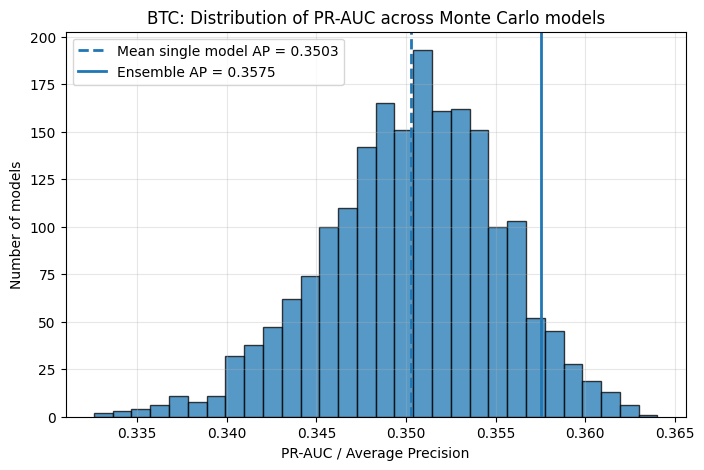

ETH: Monte Carlo subsampling
Horizon: 5 minutes
Target quantile: 0.95
Train fraction: 0.7
Number of models: 2000
Sample fraction: 0.6
Replace: False
Train size: 90556
Test size: 38811
Event threshold: 404,263.1035
Test positive rate: 6.4982%

Single models PR-AUC statistics:
Mean PR-AUC: 0.274066
Std PR-AUC:  0.005057
Var PR-AUC:  0.000026
Min PR-AUC:  0.248540
Max PR-AUC:  0.289024

Ensemble:
Ensemble PR-AUC:  0.280358


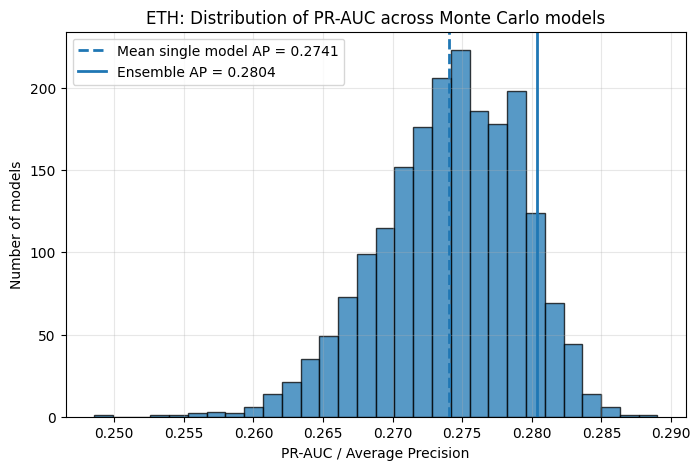

In [24]:
# monte-carlo for btc.
btc_mc = monte_carlo_simulation(
    df              = df_btc,
    asset_name      = "BTC",
    feature_cols    = feature_cols,
    horizon         = 5,
    quantile        = 0.95,
    train_frac      = 0.70,
    n_models        = 2000,
    sample_frac     = 0.60,
    replace         = False,
    random_state    = 42
)

# monte-carlo for eth.
btc_mc = monte_carlo_simulation(
    df              = df_eth,
    asset_name      = "ETH",
    feature_cols    = feature_cols,
    horizon         = 5,
    quantile        = 0.95,
    train_frac      = 0.70,
    n_models        = 2000,
    sample_frac     = 0.60,
    replace         = False,
    random_state    = 42
)

## <b>Result: Monte-Carlo Simulation.</b>

For BTC, the Monte Carlo distribution of PR-AUC is around 0.350: 
- $mean PR-AUC = 0.3503$
- $std PR-AUC=0.0049$

For ETH, the Monte Carlo distribution of PR-AUC is around 0.274:
- $mean PR-AUC = 0.2741$
- $std PR-AUC=0.0051$

Thus, for both BTC and ETH, the standard deviation of PR-AUC is small. This means that the model quality is stable to random changes in the training subset. The ensemble also improves the PR-AUC compared with the average individual model.

## <b>2. Walk-forward Monte Carlo Simulation.</b>

Monte Carlo subsampling on a single train/test split checks stability with respect to random training subsets, but it does not test stability across different time periods. Since market data are time-dependent and may contain regime changes, i additionally performed walk-forward Monte Carlo validation.

The walk-forward scheme is:

- fold 1: train [0, t1) -> test [t1, t2)
- fold 2: train [0, t2) -> test [t2, t3)
- ...
- fold k: train [0, tk) -> test [tk, T)

In each fold, the training window expands, while the test window is always located strictly in the future. Inside each fold, i repeat the same Monte Carlo subsampling procedure.

In [43]:
def monte_carlo_on_fixed_split(
    X_train,
    X_test,
    y_train_raw,
    y_test_raw,
    asset_name: str,
    fold: int,
    quantile: float = 0.95,
    sample_frac: float = 0.60,
    n_models: int = 2000,
    replace: bool = False,
    random_state: int = 42
):
    """
    Monte Carlo subsampling on one fixed walk-forward split.

    Train/test split is already fixed outside this function.
    """

    # event threshold is calculated only for train.
    event_threshold = y_train_raw.quantile(quantile)

    # target -> [0 ; 1].
    y_train = (y_train_raw > event_threshold).astype(int)
    y_test  = (y_test_raw > event_threshold).astype(int)

    n_train = len(X_train)
    sample_size = int(sample_frac * n_train)

    # random.
    rng = np.random.default_rng(random_state)

    # values.
    models = []
    pr_auc_values = []
    proba_test_all = []

    # train N models.
    for i in range(n_models):

        # train random subsample.
        idx = rng.choice(
            n_train,
            size    = sample_size,
            replace = replace
        )
        X_sub = X_train.take(idx)
        y_sub = y_train.take(idx)

        # initialize model.
        model = XGBClassifier(
            max_depth           = 4,
            learning_rate       = 0.05,
            reg_lambda          = 1.0,
            random_state        = random_state + i,
            subsample           = 0.6,
            eval_metric         = "logloss"
        )

        # fit.
        model.fit(X_sub, y_sub)

        # prediction.
        proba_test_i = model.predict_proba(X_test)[:, 1]

        # pr.
        pr_auc_i = average_precision_score(y_test, proba_test_i)

        # save result.
        models.append(model)
        proba_test_all.append(proba_test_i)
        pr_auc_values.append(pr_auc_i)

    # result.
    proba_test_all  = np.vstack(proba_test_all)
    pr_auc_values   = np.array(pr_auc_values)

    # ensemble prediction.
    proba_ensemble = proba_test_all.mean(axis=0)
    ensemble_pr_auc = average_precision_score(np.asarray(y_test), proba_ensemble)

    # return.
    result = {
        "asset": asset_name,
        "fold": fold,

        "models": models,

        "y_train": y_train,
        "y_test": y_test,

        "proba_test_all": proba_test_all,
        "proba_ensemble": proba_ensemble,

        "pr_auc_values": pr_auc_values,

        "single_pr_auc_mean": pr_auc_values.mean(),
        "single_pr_auc_std": pr_auc_values.std(ddof=1),
        "single_pr_auc_var": pr_auc_values.var(ddof=1),
        "single_pr_auc_min": pr_auc_values.min(),
        "single_pr_auc_max": pr_auc_values.max(),

        "ensemble_pr_auc": ensemble_pr_auc,

        "test_positive_rate": np.asarray(y_test).mean(),
        "event_threshold": event_threshold
    }

    return result


def walk_forward_monte_carlo_simulation(
    df: pl.DataFrame,
    asset_name: str,
    feature_cols: list,
    horizon: int = 5,
    quantile: float = 0.95,
    n_folds: int = 5,
    first_train_frac: float = 0.50,
    sample_frac: float = 0.60,
    n_models: int = 2000,
    replace: bool = False,
    random_state: int = 42
):
    """
    Walk-forward Monte Carlo validation.

    Scheme:
        fold 1: train [0, t1) -> test [t1, t2)
        fold 2: train [0, t2) -> test [t2, t3)
        ...
        fold k: train [0, tk) -> test [tk, T)

    In each fold:
        1. Event threshold is calculated only on train.
        2. N models are trained on random train subsamples.
        3. Each model is evaluated on the fixed future test window.
        4. Ensemble prediction is obtained by averaging probabilities.
    """

    # name.
    raw_target_col = f"future_liq_volume_{horizon}m"

    # prepearing X(feature) and raw y(target) ones.
    X, y_raw = prepare_ml_dataset(
        df              = df,
        feature_cols    = feature_cols,
        target_col      = raw_target_col
    )

    # values for folds.
    n = len(X)

    first_train_end = int(n * first_train_frac)

    remaining = n - first_train_end
    test_size = remaining // n_folds

    fold_results = []
    fold_outputs = []

    # main loop.
    for fold in range(1, n_folds + 1):

        # train indx.
        train_start = 0
        train_end   = first_train_end + (fold - 1) * test_size

        # test indx.
        test_start = train_end
        if fold < n_folds:
            test_end = test_start + test_size
        else:
            test_end = n
        if test_end <= test_start:
            continue

        # prepearing data.
        train_idx   = np.arange(train_start, train_end)
        test_idx    = np.arange(test_start, test_end)

        X_train     = X.take(train_idx)
        X_test      = X.take(test_idx)

        y_train_raw = y_raw.take(train_idx)
        y_test_raw  = y_raw.take(test_idx)

        # monte-carlo.
        print("=" * 80)
        print(f"{asset_name}: Walk-forward Monte Carlo | Fold {fold}")
        print("=" * 80)
        print(f"Train range: [{train_start}, {train_end})")
        print(f"Test range:  [{test_start}, {test_end})")
        print(f"Train size: {len(X_train)}")
        print(f"Test size:  {len(X_test)}")

        out = monte_carlo_on_fixed_split(
            X_train     =X_train,
            X_test      =X_test,
            y_train_raw =y_train_raw,
            y_test_raw  =y_test_raw,
            asset_name  =asset_name,
            fold        =fold,
            quantile    =quantile,
            sample_frac =sample_frac,
            n_models    =n_models,
            replace     =replace,
            random_state=random_state + 10000 * fold
        )

        row = {
            "asset": asset_name,
            "fold": fold,

            "train_start": train_start,
            "train_end": train_end,
            "test_start": test_start,
            "test_end": test_end,

            "train_size": len(X_train),
            "test_size": len(X_test),

            "event_threshold": out["event_threshold"],
            "test_positive_rate": out["test_positive_rate"],

            "single_pr_auc_mean": out["single_pr_auc_mean"],
            "single_pr_auc_std": out["single_pr_auc_std"],
            "single_pr_auc_min": out["single_pr_auc_min"],
            "single_pr_auc_max": out["single_pr_auc_max"],

            "ensemble_pr_auc": out["ensemble_pr_auc"]
        }

        fold_results.append(row)
        fold_outputs.append(out)

        print("\nFold result:")
        print(f"Mean single PR-AUC: {out['single_pr_auc_mean']:.6f}")
        print(f"Std single PR-AUC:  {out['single_pr_auc_std']:.6f}")
        print(f"Ensemble PR-AUC:    {out['ensemble_pr_auc']:.6f}")
        print(f"Test positive rate: {out['test_positive_rate']:.4%}")

    # summury result.
    results_df = pd.DataFrame(fold_results)

    print("=" * 80)
    print(f"{asset_name}: Walk-forward Monte Carlo summary")
    print("=" * 80)

    display(results_df)

    print("\nSummary across folds:")
    print(f"Mean ensemble PR-AUC: {results_df['ensemble_pr_auc'].mean():.6f}")
    print(f"Std ensemble PR-AUC:  {results_df['ensemble_pr_auc'].std(ddof=1):.6f}")
    print(f"Mean single PR-AUC:   {results_df['single_pr_auc_mean'].mean():.6f}")
    print(f"Mean inner std:       {results_df['single_pr_auc_std'].mean():.6f}")

    return results_df, fold_outputs


def plot_walk_forward_monte_carlo_results(
    results_df: pd.DataFrame,
    asset_name: str,
):
    """
    Plots ensemble PR-AUC and mean single-model PR-AUC by walk-forward fold.
    """

    plt.figure(figsize=(8, 5))

    plt.plot(
        results_df["fold"],
        results_df["ensemble_pr_auc"],
        marker      = "o",
        linewidth   = 2,
        label       = "Ensemble PR-AUC"
    )

    plt.plot(
        results_df["fold"],
        results_df["single_pr_auc_mean"],
        marker      = "o",
        linestyle   = "--",
        linewidth   = 2,
        label       = "Mean single-model PR-AUC"
    )

    plt.fill_between(
        results_df["fold"],
        results_df["single_pr_auc_mean"] - results_df["single_pr_auc_std"],
        results_df["single_pr_auc_mean"] + results_df["single_pr_auc_std"],
        alpha   = 0.2,
        label   = "Single-model ±1 std"
    )

    plt.title(f"{asset_name}: Walk-forward Monte Carlo PR-AUC")
    plt.xlabel("Fold")
    plt.ylabel("PR-AUC / Average Precision")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

BTC: Walk-forward Monte Carlo | Fold 1
Train range: [0, 64700)
Test range:  [64700, 77640)
Train size: 64700
Test size:  12940

Fold result:
Mean single PR-AUC: 0.295123
Std single PR-AUC:  0.006207
Ensemble PR-AUC:    0.300478
Test positive rate: 3.8640%
BTC: Walk-forward Monte Carlo | Fold 2
Train range: [0, 77640)
Test range:  [77640, 90580)
Train size: 77640
Test size:  12940

Fold result:
Mean single PR-AUC: 0.354743
Std single PR-AUC:  0.004949
Ensemble PR-AUC:    0.360679
Test positive rate: 6.3679%
BTC: Walk-forward Monte Carlo | Fold 3
Train range: [0, 90580)
Test range:  [90580, 103520)
Train size: 90580
Test size:  12940

Fold result:
Mean single PR-AUC: 0.438426
Std single PR-AUC:  0.006257
Ensemble PR-AUC:    0.446631
Test positive rate: 12.5425%
BTC: Walk-forward Monte Carlo | Fold 4
Train range: [0, 103520)
Test range:  [103520, 116460)
Train size: 103520
Test size:  12940

Fold result:
Mean single PR-AUC: 0.214074
Std single PR-AUC:  0.003771
Ensemble PR-AUC:    0.21729

,asset,fold,train_start,train_end,test_start,test_end,train_size,test_size,event_threshold,test_positive_rate,single_pr_auc_mean,single_pr_auc_std,single_pr_auc_min,single_pr_auc_max,ensemble_pr_auc
0,BTC,1,0,64700,64700,77640,64700,12940,467250.685300,0.038640,0.295123,0.006207,0.274641,0.314452,0.300478
1,BTC,2,0,77640,77640,90580,77640,12940,442114.207680,0.063679,0.354743,0.004949,0.344029,0.368857,0.360679
2,BTC,3,0,90580,90580,103520,90580,12940,467508.617476,0.125425,0.438426,0.006257,0.417760,0.451734,0.446631
3,BTC,4,0,103520,103520,116460,103520,12940,587353.876160,0.043509,0.214074,0.003771,0.205444,0.224728,0.217290
4,BTC,5,0,116460,116460,129401,116460,12941,577100.094870,0.054633,0.245486,0.003708,0.235050,0.257293,0.247783



Summary across folds:
Mean ensemble PR-AUC: 0.314572
Std ensemble PR-AUC:  0.091773
Mean single PR-AUC:   0.309570
Mean inner std:       0.004979




ETH: Walk-forward Monte Carlo | Fold 1
Train range: [0, 64683)
Test range:  [64683, 77619)
Train size: 64683
Test size:  12936

Fold result:
Mean single PR-AUC: 0.282304
Std single PR-AUC:  0.006889
Ensemble PR-AUC:    0.288243
Test positive rate: 4.4527%
ETH: Walk-forward Monte Carlo | Fold 2
Train range: [0, 77619)
Test range:  [77619, 90555)
Train size: 77619
Test size:  12936

Fold result:
Mean single PR-AUC: 0.350440
Std single PR-AUC:  0.005553
Ensemble PR-AUC:    0.355579
Test positive rate: 6.7409%
ETH: Walk-forward Monte Carlo | Fold 3
Train range: [0, 90555)
Test range:  [90555, 103491)
Train size: 90555
Test size:  12936

Fold result:
Mean single PR-AUC: 0.344766
Std single PR-AUC:  0.007121
Ensemble PR-AUC:    0.352451
Test positive rate: 10.0186%
ETH: Walk-forward Monte Carlo | Fold 4
Train range: [0, 103491)
Test range:  [1

,asset,fold,train_start,train_end,test_start,test_end,train_size,test_size,event_threshold,test_positive_rate,single_pr_auc_mean,single_pr_auc_std,single_pr_auc_min,single_pr_auc_max,ensemble_pr_auc
0,ETH,1,0,64683,64683,77619,64683,12936,388528.995990,0.044527,0.282304,0.006889,0.248542,0.304173,0.288243
1,ETH,2,0,77619,77619,90555,77619,12936,378913.136719,0.067409,0.350440,0.005553,0.330368,0.365937,0.355579
2,ETH,3,0,90555,90555,103491,90555,12936,404263.103530,0.100186,0.344766,0.007121,0.323934,0.364730,0.352451
3,ETH,4,0,103491,103491,116427,103491,12936,466400.738005,0.037338,0.154915,0.002900,0.145797,0.163579,0.157413
4,ETH,5,0,116427,116427,129367,116427,12940,449775.534069,0.046445,0.205360,0.003590,0.195186,0.214489,0.208079



Summary across folds:
Mean ensemble PR-AUC: 0.272353
Std ensemble PR-AUC:  0.087944
Mean single PR-AUC:   0.267557
Mean inner std:       0.005211


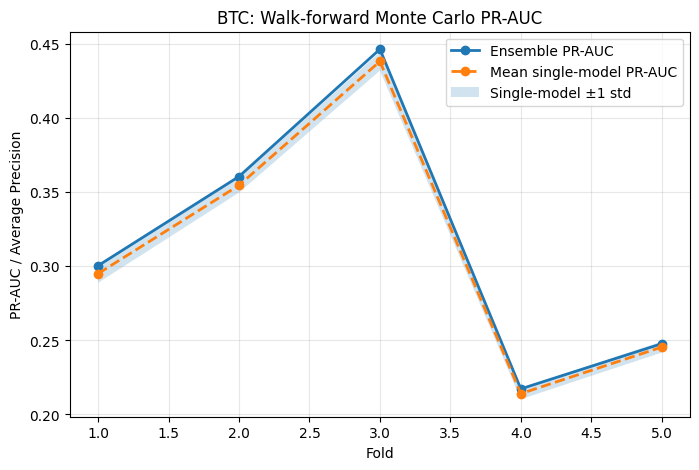

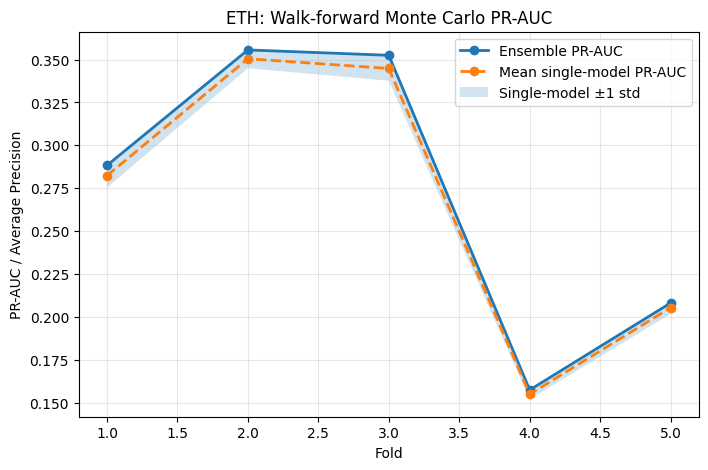

In [45]:
# btc walk-forward monte-carlo simulation.
btc_wf_mc_results, btc_wf_mc_outputs = walk_forward_monte_carlo_simulation(
    df              = df_btc,
    asset_name      = "BTC",
    feature_cols    = feature_cols,
    horizon         = 5,
    quantile        = 0.95,
    n_folds         = 5,
    first_train_frac= 0.50,
    sample_frac     = 0.60,
    n_models        = 200,
    replace         = False,
    random_state    = 42
)

print("\n\n\n")

# eth walk-forward monte-carlo simulation.
eth_wf_mc_results, eth_wf_mc_outputs = walk_forward_monte_carlo_simulation(
    df              = df_eth,
    asset_name      = "ETH",
    feature_cols    = feature_cols,
    horizon         = 5,
    quantile        = 0.95,
    n_folds         = 5,
    first_train_frac= 0.50,
    sample_frac     = 0.60,
    n_models        = 200,
    replace         = False,
    random_state    = 42
)

# btc walk-forward monte-carlo pr per-fold.
plot_walk_forward_monte_carlo_results(
    results_df  = btc_wf_mc_results,
    asset_name  = "BTC"
)

# eth walk-forward monte-carlo pr per-fold.
plot_walk_forward_monte_carlo_results(
    results_df  = eth_wf_mc_results,
    asset_name  = "ETH"
)

## <b>Result: Walk-forward Monte Carlo Simulation.</b>

- The walk-forward Monte Carlo results show that the inner Monte Carlo standard deviation remains low in each fold. Therefore, within a fixed fold, the model is stable with respect to random train subsampling.

- However, the ensemble PR-AUC changes noticeably across folds.

- This means that the model contains a stable predictive signal, but this signal is regime-dependent. In some market periods, the liquidation dynamics are highly predictable, while in other periods the same features provide weaker ranking quality.

## <b>3. Calibration Curve on walk-forward.</b>

- After evaluating ranking quality with PR-AUC, i checked whether the predicted probabilities can be interpreted as calibrated risk estimates.

- For this purpose, we used calibration curves. The predicted probabilities were divided into bins, and for each bin algo compared: `mean predicted probability` and `actual positive event frequency`.

- This check is important because a model may have good ranking quality but poorly calibrated probabilities. In that case, the predicted probability can still be used as a risk score, but not as a direct estimate of event probability.

In [50]:
def plot_walk_forward_calibration_curves(
    fold_outputs,
    asset_name: str,
    n_bins: int = 10,
):
    """
    Builds calibration curves for all walk-forward folds.
    """

    plt.figure(figsize=(7, 5))

    rows = []

    for out in fold_outputs:

        fold    = out["fold"]
        y_true  = np.asarray(out["y_test"])
        proba   = np.asarray(out["proba_ensemble"])

        frac_pos, mean_pred = calibration_curve(
            y_true,
            proba,
            n_bins      = n_bins,
            strategy    = "quantile"
        )

        brier = brier_score_loss(y_true, proba)

        plt.plot(
            mean_pred,
            frac_pos,
            marker      = "o",
            linewidth   = 2,
            label       = f"Fold {fold}, Brier = {brier:.4f}"
        )

        for x, y in zip(mean_pred, frac_pos):
            rows.append({
                "asset": asset_name,
                "fold": fold,
                "mean_predicted_probability": x,
                "actual_positive_frequency": y,
                "brier_score": brier
            })

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle   = "--",
        linewidth   = 2,
        label       = "Perfect calibration"
    )

    plt.title(f"{asset_name}: Walk-forward calibration curves")
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Actual positive frequency")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    return pd.DataFrame(rows)

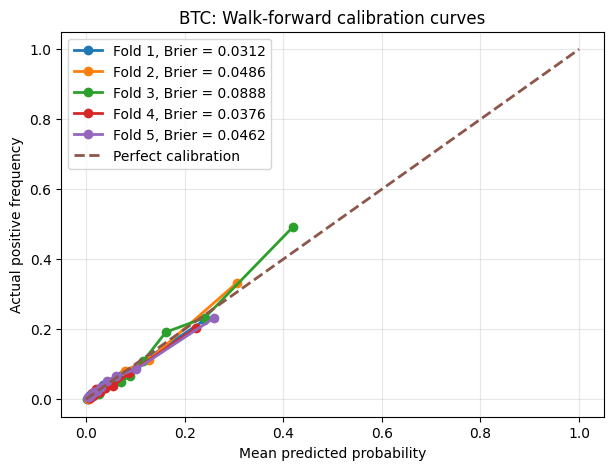

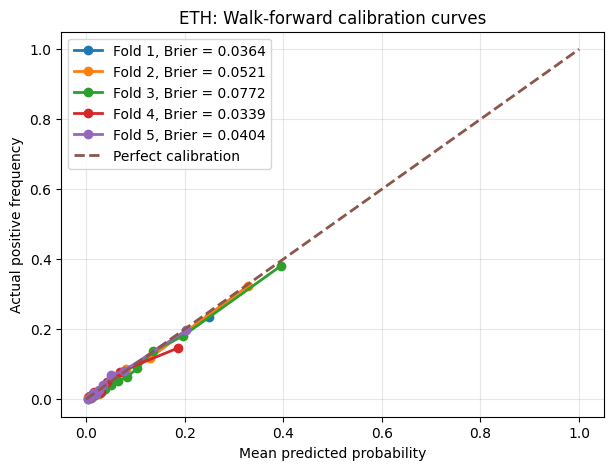

In [53]:
btc_wf_calibration = plot_walk_forward_calibration_curves(
    fold_outputs    = btc_wf_mc_outputs,
    asset_name      = "BTC",
    n_bins          = 10
)

eth_wf_calibration = plot_walk_forward_calibration_curves(
    fold_outputs    = eth_wf_mc_outputs,
    asset_name      = "ETH",
    n_bins          = 10
)

## <b>Result: Calibration Curve on walk-forward.</b>

- For BTC and ETH, the calibration curves are mostly close to the diagonal line. This means that the ensemble probabilities are reasonably calibrated.

- Overall, the calibration analysis shows that the ensemble probabilities are not only useful for ranking but can also be interpreted as approximate risk probabilities.

## <b>4. Permutation importance.</b>

- After checking the stability and calibration of the model, i analyze which features actually contribute to the out-of-sample predictive performance.

- For this purpose, i use permutation importance. The idea is to randomly shuffle one feature in the test set while keeping all other features unchanged. Then i recompute the model prediction and measure how much PR-AUC decreases.

In [56]:
def predict_ensemble_proba(models, X):
    """
    Predicts class-1 probability averaged over all models.
    """

    proba_all = []

    for model in models:
        proba_i = model.predict_proba(X)[:, 1]
        proba_all.append(proba_i)

    proba_all = np.vstack(proba_all)

    return proba_all.mean(axis=0)


def shuffle_one_feature(X, feature_name, rng):
    """
    Randomly permutes one feature column in X.

    Works for pandas DataFrame.
    """

    X_perm = X.copy()

    values = X_perm[feature_name].to_numpy().copy()
    rng.shuffle(values)

    X_perm[feature_name] = values

    return X_perm


def permutation_importance_monte_carlo(
    mc_result: dict,
    feature_cols: list,
    asset_name: str,
    n_repeats: int = 5,
    random_state: int = 42,
):
    """
    Computes permutation importance for Monte Carlo ensemble.

    For each feature:
        1. Shuffle this feature in X_test.
        2. Predict with the ensemble.
        3. Compute PR-AUC.
        4. Compute PR-AUC drop.
    """

    rng = np.random.default_rng(random_state)

    X_test = mc_result["X_test"]
    y_test = np.asarray(mc_result["y_test"])
    models = mc_result["models"]

    base_proba = mc_result["proba_ensemble"]
    base_pr_auc = average_precision_score(y_test, base_proba)

    rows = []

    for feature in feature_cols:

        perm_pr_auc_values = []

        for repeat in range(n_repeats):

            X_perm = shuffle_one_feature(
                X           = X_test,
                feature_name= feature,
                rng         = rng
            )

            perm_proba = predict_ensemble_proba(
                models  = models,
                X       = X_perm
            )

            perm_pr_auc = average_precision_score(
                y_test,
                perm_proba
            )

            perm_pr_auc_values.append(perm_pr_auc)

        perm_pr_auc_mean = np.mean(perm_pr_auc_values)
        perm_pr_auc_std = np.std(perm_pr_auc_values, ddof=1)

        rows.append({
            "asset": asset_name,
            "feature": feature,

            "base_pr_auc": base_pr_auc,
            "perm_pr_auc_mean": perm_pr_auc_mean,
            "perm_pr_auc_std": perm_pr_auc_std,
            "pr_auc_drop": base_pr_auc - perm_pr_auc_mean,
        })

    importance_df = pd.DataFrame(rows)

    importance_df = (
        importance_df
        .sort_values("pr_auc_drop", ascending=False)
        .reset_index(drop=True)
    )

    return importance_df

def plot_permutation_importance(
    importance_df: pd.DataFrame,
    asset_name: str,
    top_n: int = 25,
):
    """
    Plots top-N features by PR-AUC drop.
    """

    plot_df = importance_df.head(top_n).copy()

    plot_df = plot_df.sort_values(
        "pr_auc_drop",
        ascending=True,
    )

    plt.figure(figsize=(9, 7))

    plt.barh(
        plot_df["feature"],
        plot_df["pr_auc_drop"],
        xerr=plot_df["perm_pr_auc_std"],
    )

    plt.title(f"{asset_name}: Permutation importance by PR-AUC drop")
    plt.xlabel("PR-AUC drop after feature shuffling")
    plt.ylabel("Feature")
    plt.grid(alpha=0.3)
    plt.show()

In [ ]:
# premutation importance for btc.
btc_perm = permutation_importance_monte_carlo(
    mc_result       = btc_mc,
    feature_cols    = feature_cols,
    asset_name      = "BTC",
    n_repeats       = 5,
    random_state    = 42
)

display(btc_perm.head(30))

,asset,feature,base_pr_auc,perm_pr_auc_mean,perm_pr_auc_std,pr_auc_drop
0,BTC,trade_volume,0.280358,0.151417,0.004967,0.128940
1,BTC,abs_return_mean_15m,0.280358,0.255122,0.003930,0.025236
2,BTC,liq_total_sum_15m,0.280358,0.260414,0.002161,0.019944
3,BTC,liq_imbalance_60m,0.280358,0.269946,0.000911,0.010412
4,BTC,liq_imbalance,0.280358,0.275594,0.001536,0.004764
5,BTC,liq_total_volume,0.280358,0.277107,0.000331,0.003251
6,BTC,trade_imbalance,0.280358,0.277145,0.000615,0.003213
7,BTC,amihud_per_1m_usd,0.280358,0.279337,0.000311,0.001021
8,BTC,half_spread_bps,0.280358,0.279421,0.000233,0.000936
9,BTC,abs_return_1m,0.280358,0.279595,0.000061,0.000763


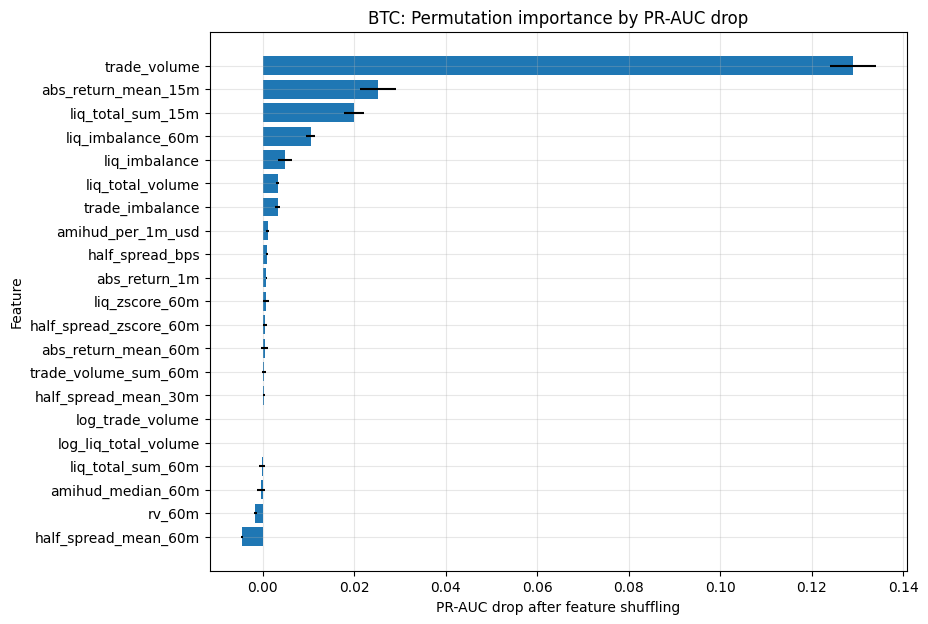

In [ ]:
# plot premutation importance for btc.
plot_permutation_importance(
    importance_df   = btc_perm,
    asset_name      = "BTC",
    top_n           = 25
)

## <b>Result: Permutation importance.</b>

- The permutation importance results show that the BTC model relies mainly on trading volume and liquidation-related features.

- But the model uses not only current market activity, but also recent liquidation dynamics.

- The permutation importance analysis suggests that the model is not a black-box classifier relying. Its signals are economically interpretable.